# Training

In [13]:
# import the libs
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import confusion_matrix, classification_report, f1_score, precision_score, recall_score, accuracy_score
from sklearn.tree import plot_tree
import pandas as pd
import joblib
import matplotlib.pyplot as plt
import seaborn as sns

exo_plnt = pd.read_csv(r"..\Visualization and data cleaning\Cleaned_dataset.csv")
exo_plnt

,koi_period,koi_impact,koi_duration,koi_depth,koi_prad,koi_teq,koi_insol,koi_model_snr,koi_tce_plnt_num,koi_steff,koi_slogg,koi_srad,koi_kepmag,encoded_disposition
0,9.488036,0.146,2.95750,615.8,2.26,793.0,93.59,35.8,1.0,5455.0,4.467,0.927,15.347,1
1,54.418383,0.586,4.50700,874.8,2.83,443.0,9.11,25.8,2.0,5455.0,4.467,0.927,15.347,1
2,19.899140,0.969,1.78220,10829.0,14.60,638.0,39.30,76.3,1.0,5853.0,4.544,0.868,15.436,0
3,1.736952,1.276,2.40641,8079.2,33.46,1395.0,891.96,505.6,1.0,5805.0,4.564,0.791,15.597,0
4,2.525592,0.701,1.65450,603.3,2.75,1406.0,926.16,40.9,1.0,6031.0,4.438,1.046,15.509,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6804,23.627035,1.096,11.48100,8433.0,21.71,560.0,23.17,78.4,1.0,5305.0,4.477,0.857,16.375,0
6805,8.589871,0.765,4.80600,87.7,1.11,929.0,176.40,8.4,1.0,5638.0,4.296,1.088,14.478,0
6806,0.527699,1.252,3.22210,1579.2,29.35,2088.0,4500.53,453.3,1.0,5638.0,4.529,0.903,14.082,0
6807,0.681402,0.147,0.86500,103.6,1.07,2218.0,5713.41,12.3,1.0,6173.0,4.447,1.041,15.385,0


In [5]:
# splitting the data
X_train, X_test, y_train, y_test = train_test_split(
    exo_plnt.drop(columns='encoded_disposition'),
    exo_plnt['encoded_disposition'], 
    test_size=0.2, 
    random_state=42
)

In [6]:
# intitializing the model
model = RandomForestClassifier()

# training
model.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [22]:
# testing
# predictions = model.predict(X_test)

custom_predictions = (model.predict_proba(X_test)[:, 1] >= 0.18).astype(int)

In [23]:
# performance metrics
confusion_mat = confusion_matrix(y_test, custom_predictions)
print('Confusion Matrix: \n', confusion_mat)
print('Classification Report: \n', classification_report(y_test, custom_predictions))

Confusion Matrix: 
 [[727 163]
 [  8 464]]
Classification Report: 
               precision    recall  f1-score   support

           0       0.99      0.82      0.89       890
           1       0.74      0.98      0.84       472

    accuracy                           0.87      1362
   macro avg       0.86      0.90      0.87      1362
weighted avg       0.90      0.87      0.88      1362



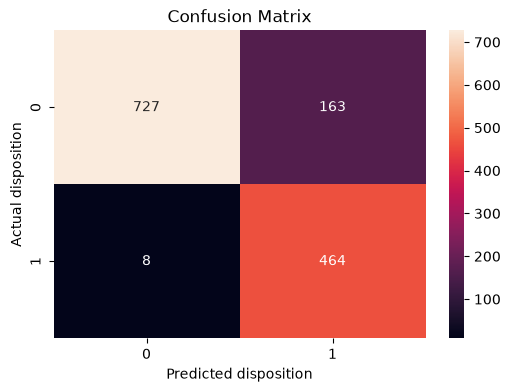

Accuracy: 87.44%
Precision: 74.00%
Recall: 98.31%
F1-score: 84.44%


In [25]:
# confusion matrix heatmap
plt.figure(figsize=(6, 4))

sns.heatmap(
    confusion_mat, 
    annot=True, 
    fmt='g'
)

plt.title('Confusion Matrix')
plt.xlabel('Predicted disposition')
plt.ylabel('Actual disposition')

plt.savefig('Confusion_matrix.png', dpi=1000)

plt.show()

print(f"Accuracy: {accuracy_score(y_test, custom_predictions)*100:.2f}%")
print(f"Precision: {precision_score(y_test, custom_predictions)*100:.2f}%")
print(f"Recall: {recall_score(y_test, custom_predictions)*100:.2f}%")
print(f"F1-score: {f1_score(y_test, custom_predictions)*100:.2f}%")

In [26]:
# pickling the trained model
joblib.dump(model, 'exoplanet_model.pkl')

print('Model saved successfully!')

Model saved successfully!


In [27]:
# finding meadians of all columns
exo_plnt.median(axis=0)

koi_period                7.834434
koi_impact                0.587000
koi_duration              3.890000
koi_depth               515.200000
koi_prad                  2.720000
koi_teq                 939.000000
koi_insol               183.480000
koi_model_snr            32.100000
koi_tce_plnt_num          1.000000
koi_steff              5774.000000
koi_slogg                 4.438000
koi_srad                  1.000000
koi_kepmag               14.492000
encoded_disposition       0.000000
dtype: float64

In [28]:
print(custom_predictions)
model.predict_proba(X_test)

[1 0 1 ... 1 0 1]


array([[0.32, 0.68],
       [0.98, 0.02],
       [0.58, 0.42],
       ...,
       [0.03, 0.97],
       [0.99, 0.01],
       [0.67, 0.33]], shape=(1362, 2))

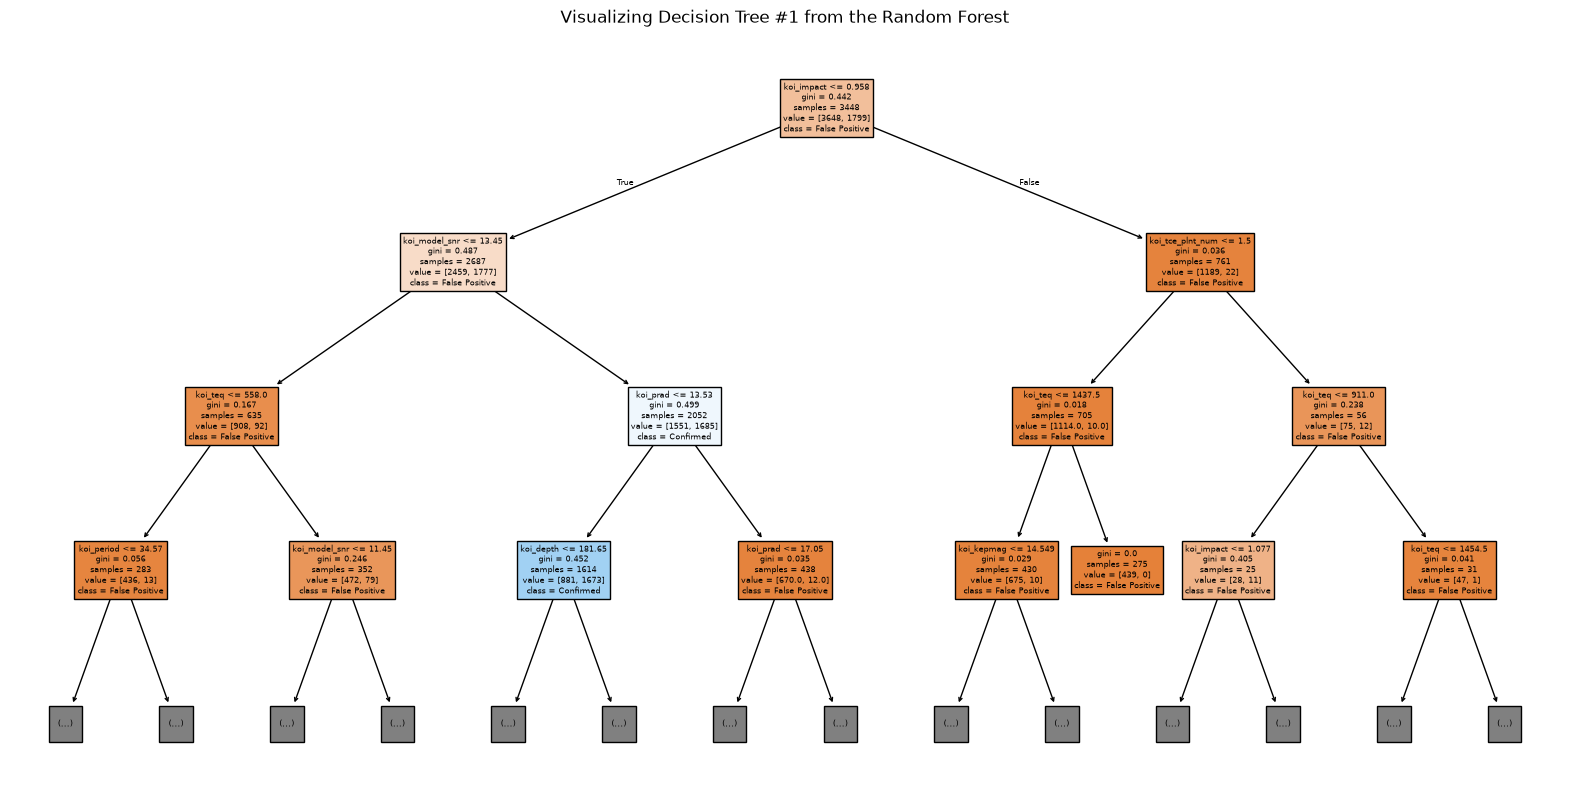

In [31]:
model = joblib.load(r"exoplanet_model.pkl")

# 1. Set up a large figure size so you can read the text
plt.figure(figsize=(20, 10))

# 2. Plot the first tree in your Random Forest
plot_tree(
    model.estimators_[0],          # Pulls the 1st tree (change 0 to 1, 2, etc. for others)
    feature_names=X_train.columns, # Labels the splits with your feature names (e.g., koi_depth)
    class_names=['False Positive', 'Confirmed'], # Labels the predictions
    filled=True,                   # Colors the nodes (blue for Confirmed, orange for False Positive)
    max_depth=3                    # Limits the view to the top 3 levels so it is readable
)

plt.title("Visualizing Decision Tree #1 from the Random Forest")

plt.savefig('decision_tree1.png', dpi=1000)
plt.show()
